# 06 · Final model, threshold and test-set evaluation
Loads the model selected in notebook 05, fixes the decision threshold on training data, then evaluates on the held-out test set. Outputs are risk scores used for ranking, not calibrated probabilities.

## 1. Setup: load training data and the selected model
**What it does:** loads `train.csv`, defines the same three candidate models as notebook 05, and reads the winner from `results/selected_model.txt`.

**Why:** guarantees the final evaluation uses the model chosen by cross-validation, not one picked by hand.

In [ ]:
import pandas as pd, numpy as np, warnings, os
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
pd.set_option("display.width", 200)
os.makedirs("images", exist_ok=True)

train = pd.read_csv("data/train.csv")
X_train, y_train = train.drop(columns="Bankrupt?"), train["Bankrupt?"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Same model definitions as notebook 05
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
candidates = {
    "Logistic Regression": Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=42)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=42),
}
MODEL_NAME = open("results/selected_model.txt").read().strip()   # winner of notebook 05
final_model = candidates[MODEL_NAME]
print("Final model (selected in notebook 05):", MODEL_NAME)

Final model (selected in notebook 05): XGBoost


## 2. Fix the threshold at 10% review capacity (training data only)
**What it does:** produces out-of-fold risk scores on the training set and takes the score at the 10% cut-off as the decision threshold.

**Why:** the threshold is chosen before the test set is opened, so the test result stays an honest estimate. 10% is an assumed analyst workload.

In [ ]:
oof_scores = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
CAPACITY = 0.10
k = int(round(CAPACITY * len(oof_scores)))
THRESHOLD = float(np.sort(oof_scores)[::-1][k - 1])
print(f"Threshold for {CAPACITY:.0%} review capacity (from training CV): {THRESHOLD:.4f}")

Threshold for 10% review capacity (from training CV): 0.0190


## 3. Train the final model on all training data
**What it does:** refits the selected model on all 5,455 training records.

**Why:** the final model uses all available training data; the threshold from step 2 is kept unchanged.

In [ ]:
final_model.fit(X_train, y_train)
print("Final model trained on", len(X_train), "companies")

Final model trained on 5455 companies


## 4. Open the held-out test set
**What it does:** loads `test.csv` for the first time and computes a risk score for each of the 1,364 test records.

**Why:** the model and threshold are already fixed, so nothing below changes them.

In [ ]:
test = pd.read_csv("data/test.csv")
X_test, y_test = test.drop(columns="Bankrupt?"), test["Bankrupt?"]
test_scores = final_model.predict_proba(X_test)[:, 1]
print("Test set:", len(X_test), "companies |", int(y_test.sum()), "bankrupt")

Test set: 1364 companies | 44 bankrupt


## 5. Final test metrics at the fixed threshold
**What it does:** reports ROC-AUC and PR-AUC (ranking quality) and recall, precision and F1 at the fixed threshold, plus how many records were flagged, caught, missed and falsely flagged.

**Why:** shows how the screening tool would have performed on records it never saw.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
y_pred = (test_scores >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
final = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "PR-AUC": average_precision_score(y_test, test_scores),
    "Recall (at threshold)": recall_score(y_test, y_pred),
    "Precision (at threshold)": precision_score(y_test, y_pred, zero_division=0),
    "F1 (at threshold)": f1_score(y_test, y_pred, zero_division=0),
}).round(3)
print(final)
print(f"\nFlagged: {tp+fp} of {len(y_test)} companies ({(tp+fp)/len(y_test):.1%})")
print(f"Bankruptcies caught: {tp} of {tp+fn} | missed: {fn} | false alarms: {fp}")

ROC-AUC                     0.963
PR-AUC                      0.533
Recall (at threshold)       0.841
Precision (at threshold)    0.252
F1 (at threshold)           0.387
dtype: float64

Flagged: 147 of 1364 companies (10.8%)
Bankruptcies caught: 37 of 44 | missed: 7 | false alarms: 110


## 6. Review-capacity table on the test set
**What it does:** ranks the test records and counts bankruptcies found when reviewing exactly the top 5%, 10%, 15% and 20%.

**Why:** lets a reader pick a different workload and see the trade-off between bankruptcies caught and records reviewed.

In [ ]:
def capacity_table(scores, y_true, capacities=(0.05, 0.10, 0.15, 0.20)):
    y_true = np.asarray(y_true); order = np.argsort(-scores); out = []
    for cap in capacities:
        kk = int(round(cap * len(scores))); c = int(y_true[order[:kk]].sum())
        out.append({"capacity": f"{int(cap*100)}%", "companies_reviewed": kk,
                    "bankruptcies_caught": c, "recall": round(c / y_true.sum(), 3),
                    "precision": round(c / kk, 3)})
    return pd.DataFrame(out)
print(capacity_table(test_scores, y_test).to_string(index=False))

capacity  companies_reviewed  bankruptcies_caught  recall  precision
      5%                  68                   30   0.682      0.441
     10%                 136                   36   0.818      0.265
     15%                 205                   41   0.932      0.200
     20%                 273                   42   0.955      0.154


## 7. Charts for the README
**What it does:** draws the precision-recall curve with the chosen threshold marked, and the confusion matrix, and saves both to `images/`.

**Why:** these are the figures shown in the README.

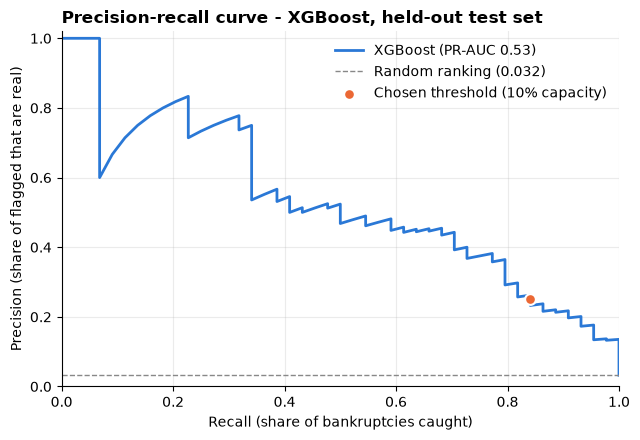

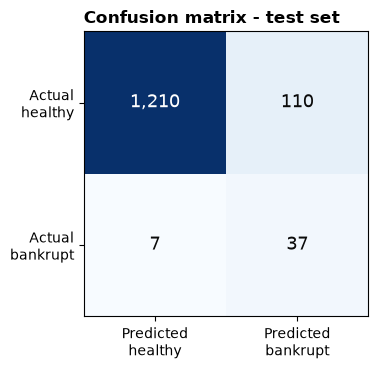

In [ ]:
from sklearn.metrics import precision_recall_curve
p, r, _ = precision_recall_curve(y_test, test_scores)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(r, p, color="#2a78d6", linewidth=2, label=f"{MODEL_NAME} (PR-AUC {final['PR-AUC']:.2f})")
ax.axhline(y_test.mean(), color="#888", linestyle="--", linewidth=1, label=f"Random ranking ({y_test.mean():.3f})")
ax.scatter([final["Recall (at threshold)"]], [final["Precision (at threshold)"]], color="#eb6834",
           s=60, zorder=3, edgecolor="white", linewidth=1.5, label="Chosen threshold (10% capacity)")
ax.set_xlabel("Recall (share of bankruptcies caught)"); ax.set_ylabel("Precision (share of flagged that are real)")
ax.set_title(f"Precision-recall curve - {MODEL_NAME}, held-out test set", loc="left", fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("images/pr_curve_test.png", dpi=150); plt.show()

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=13,
            color="white" if v > cm.max() / 2 else "#0b0b0b")
ax.set_xticks([0, 1], ["Predicted\nhealthy", "Predicted\nbankrupt"])
ax.set_yticks([0, 1], ["Actual\nhealthy", "Actual\nbankrupt"])
ax.set_title("Confusion matrix - test set", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("images/confusion_matrix_test.png", dpi=150); plt.show()

## 8. Which ratios drive the predictions? (permutation importance)
**What it does:** shuffles each feature 20 times on the test set and measures the average drop in PR-AUC; plots the top 10 and saves the chart to `images/`.

**Why:** shows which ratios the model relies on most. This is predictive importance, not causation.

                                feature  importance    std
    Interest-bearing debt interest rate      0.0825 0.0228
                            Quick Ratio      0.0529 0.0303
                     Revenue per person      0.0354 0.0125
                   Borrowing dependency      0.0304 0.0194
Persistent EPS in the Last Four Seasons      0.0248 0.0102
             Allocation rate per person      0.0231 0.0059
                  Net Value Growth Rate      0.0222 0.0122
          Equity to Long-term Liability      0.0192 0.0099
           Accounts Receivable Turnover      0.0178 0.0081
  Research and development expense rate      0.0163 0.0073


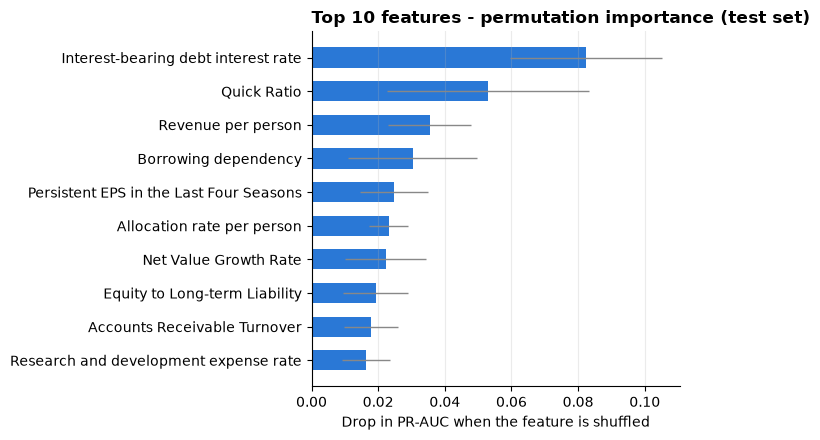

In [ ]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                            n_repeats=20, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean,
                    "std": pi.importances_std}).sort_values("importance", ascending=False)
print(imp.head(10).round(4).to_string(index=False))

top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#2a78d6", height=0.6,
        error_kw={"elinewidth": 1, "ecolor": "#888"})
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("Top 10 features - permutation importance (test set)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=150); plt.show()

## 9. Direction check for the top 5 features
**What it does:** compares the median value of the five most important features for healthy vs bankrupt records in the training data.

**Why:** indicates whether higher values go with more or less risk. This describes an association only, not the model's internal logic.

In [ ]:
top5 = imp.head(5)["feature"].tolist()
direction = train.groupby("Bankrupt?")[top5].median().T
direction.columns = ["Healthy (median)", "Bankrupt (median)"]
print(direction.round(4))

                                         Healthy (median)  Bankrupt (median)
Interest-bearing debt interest rate                0.0003             0.0005
Quick Ratio                                        0.0075             0.0028
Revenue per person                                 0.0184             0.0207
Borrowing dependency                               0.3725             0.3828
Persistent EPS in the Last Four Seasons            0.2249             0.1967
